# Berlin LOR Spatial Watering Analysis

## Mapping citizen watering at neighbourhood scale

**Objective.** Move the thesis from district summaries to a reproducible
spatial workflow by assigning Berlin's tree inventory and 2020-2025 citizen
watering records to the 542 LOR Planungsräume.

**Success criteria.**

- validate and correct the tree GeoPackage CRS;
- calculate inventory-normalized watering measures for every Planungsraum;
- map the existing district heat baseline and neighbourhood watering patterns;
- test whether neighbourhood watering reach is spatially clustered;
- export analysis-ready tables, polygons, and an interactive map.

The results are descriptive. Spatial clustering does not identify a causal
effect of watering on temperature.

## Analysis plan

1. Load the official 2021 LOR Planungsraum boundaries.
2. repair the tree layer's incorrect CRS metadata and spatially join trees to LOR.
3. Aggregate watering events to trees, then from trees to Planungsräume.
4. Map the prior district heat indicators and the new LOR watering metrics.
5. Estimate global and local Moran statistics for watering reach.
6. Export reusable spatial outputs for the next equity and heat-data joins.

In [1]:
from pathlib import Path
import warnings

import numpy as np
import pandas as pd
import geopandas as gpd
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap
import folium
from branca.colormap import linear
from esda import Moran, Moran_Local
from libpysal.weights import Queen
from IPython.display import display, HTML

warnings.filterwarnings("ignore")
pd.set_option("display.max_columns", 50)
pd.set_option("display.float_format", lambda x: f"{x:,.3f}")
np.random.seed(42)


def find_root():
    for candidate in [Path.cwd(), *Path.cwd().parents]:
        if (candidate / "data/Berlin_trees.gpkg").exists():
            return candidate
    raise FileNotFoundError("Could not locate the project root.")


ROOT = find_root()
DATA = ROOT / "data"
SPATIAL_DATA = DATA / "spatial"
OUT = ROOT / "output/spatial"
FIGURES = OUT / "figures"
TABLES = OUT / "tables"
MAPS = OUT / "maps"
for folder in [FIGURES, TABLES, MAPS]:
    folder.mkdir(parents=True, exist_ok=True)

TREE_FILE = DATA / "Berlin_trees.gpkg"
LOR_FILE = SPATIAL_DATA / "lor_planungsraeume_2021.gpkg"
WATER_FILE = next(DATA.glob("giessdenkiez_bew*sserungsdaten*.csv"))
HEAT_FILE = DATA / "Berlin_heat_population_death_Birth_data.csv"
TARGET_CRS = "EPSG:25833"

COLORS = {
    "green": "#26734d",
    "blue": "#337ab7",
    "orange": "#d9822b",
    "red": "#b23a48",
}

print(f"Project root discovered: {ROOT.name}")
print(f"LOR polygons: {LOR_FILE.name}")
print(f"Tree inventory: {TREE_FILE.name}")
print(f"Watering records: {WATER_FILE.name}")

Project root discovered: MasterThesis
LOR polygons: lor_planungsraeume_2021.gpkg
Tree inventory: Berlin_trees.gpkg
Watering records: giessdenkiez_bewässerungsdaten (1).csv


## 1. Load and validate the spatial layers

In [2]:
lor = gpd.read_file(LOR_FILE, layer="a_lor_plr_2021")
lor["District"] = lor["bez"].str.replace(r"^\d+\s*-\s*", "", regex=True)

trees = gpd.read_file(
    TREE_FILE,
    layer="Berlin_trees",
    columns=["pitid", "bezirk", "source_layer"],
)

crs_audit = pd.DataFrame(
    {
        "layer": ["LOR Planungsräume", "Tree inventory (declared)", "Tree inventory (corrected)"],
        "crs": [str(lor.crs), str(trees.crs), TARGET_CRS],
        "min_x": [lor.total_bounds[0], trees.total_bounds[0], trees.total_bounds[0]],
        "min_y": [lor.total_bounds[1], trees.total_bounds[1], trees.total_bounds[1]],
        "max_x": [lor.total_bounds[2], trees.total_bounds[2], trees.total_bounds[2]],
        "max_y": [lor.total_bounds[3], trees.total_bounds[3], trees.total_bounds[3]],
    }
)

# The tree coordinates are UTM metres, despite being declared as longitude/latitude.
assert trees.total_bounds[0] > 300_000 and trees.total_bounds[1] > 5_000_000
trees = trees.set_crs(TARGET_CRS, allow_override=True)

assert str(lor.crs) == TARGET_CRS
assert len(lor) == 542
assert lor["plr_id"].is_unique

display(crs_audit)
print(f"LOR features: {len(lor):,}")
print(f"Tree rows: {len(trees):,}")

,layer,crs,min_x,min_y,max_x,max_y
0,LOR Planungsräume,EPSG:25833,"370,000.825","5,799,520.660","415,786.553","5,837,259.270"
1,Tree inventory (declared),EPSG:4326,"370,189.476","5,799,846.613","415,496.892","5,835,818.974"
2,Tree inventory (corrected),EPSG:25833,"370,189.476","5,799,846.613","415,496.892","5,835,818.974"


LOR features: 542
Tree rows: 962,545


In [3]:
trees = trees[trees["pitid"].notna()].copy()
lor_lookup = lor[
    ["plr_id", "plr_name", "bzr_id", "bzr_name", "bez", "District", "geometry"]
]

trees_lor = gpd.sjoin(
    trees,
    lor_lookup,
    how="left",
    predicate="within",
).drop(columns="index_right")

assigned = trees_lor["plr_id"].notna()
district_agreement = (
    trees_lor.loc[assigned, "bezirk"] == trees_lor.loc[assigned, "District"]
).mean()

spatial_join_audit = pd.DataFrame(
    {
        "metric": [
            "Unique non-null tree IDs",
            "Trees assigned to a Planungsraum",
            "Trees outside/unassigned",
            "Assignment rate",
            "Tree district agrees with LOR district",
        ],
        "value": [
            trees["pitid"].nunique(),
            int(assigned.sum()),
            int((~assigned).sum()),
            assigned.mean(),
            district_agreement,
        ],
    }
)
spatial_join_audit.to_csv(TABLES / "spatial_join_audit.csv", index=False)
display(spatial_join_audit)

assert assigned.mean() > 0.99, "Unexpectedly low LOR assignment rate."
assert district_agreement > 0.99, "The corrected CRS or LOR join appears inconsistent."
trees_lor = trees_lor.loc[assigned].copy()

,metric,value
0,Unique non-null tree IDs,"956,347.000"
1,Trees assigned to a Planungsraum,"955,434.000"
2,Trees outside/unassigned,913.000
3,Assignment rate,0.999
4,Tree district agrees with LOR district,1.000


## 2. Build Planungsraum watering measures

In [4]:
water_raw = pd.read_csv(WATER_FILE, sep=";")
duplicate_mask = water_raw.duplicated(keep="first")
water = water_raw.loc[~duplicate_mask].copy()
water["timestamp"] = pd.to_datetime(
    water["timestamp"], format="mixed", utc=True, errors="coerce"
)
water["litres"] = pd.to_numeric(
    water["bewaesserungsmenge_in_liter"], errors="coerce"
)

# Keep complete calendar years and aggregate events before joining to geometry.
water = water[
    water["timestamp"].ge("2020-01-01")
    & water["timestamp"].lt("2026-01-01")
].copy()

tree_watering = (
    water.groupby("id", as_index=False)
    .agg(
        watering_events=("id", "size"),
        total_litres=("litres", "sum"),
        first_watered=("timestamp", "min"),
        last_watered=("timestamp", "max"),
    )
)

inventory = (
    trees_lor.groupby(
        ["plr_id", "plr_name", "bzr_id", "bzr_name", "District"],
        as_index=False,
    )
    .agg(
        inventory_trees=("pitid", "nunique"),
        street_inventory_trees=(
            "source_layer",
            lambda s: (s == "baumbestand:strassenbaeume").sum(),
        ),
    )
)

watered_trees = trees_lor.merge(
    tree_watering,
    left_on="pitid",
    right_on="id",
    how="inner",
)
watering_by_lor = (
    watered_trees.groupby("plr_id", as_index=False)
    .agg(
        watered_trees=("pitid", "nunique"),
        watering_events=("watering_events", "sum"),
        total_litres=("total_litres", "sum"),
    )
)

lor_metrics = (
    lor.merge(inventory, on=["plr_id", "plr_name", "bzr_id", "bzr_name", "District"], how="left")
    .merge(watering_by_lor, on="plr_id", how="left")
)

count_columns = [
    "inventory_trees",
    "street_inventory_trees",
    "watered_trees",
    "watering_events",
    "total_litres",
]
lor_metrics[count_columns] = lor_metrics[count_columns].fillna(0)
lor_metrics["watering_reach_pct"] = np.where(
    lor_metrics["inventory_trees"] > 0,
    100 * lor_metrics["watered_trees"] / lor_metrics["inventory_trees"],
    np.nan,
)
lor_metrics["litres_per_inventory_tree"] = np.where(
    lor_metrics["inventory_trees"] > 0,
    lor_metrics["total_litres"] / lor_metrics["inventory_trees"],
    np.nan,
)
lor_metrics["events_per_1000_trees"] = np.where(
    lor_metrics["inventory_trees"] > 0,
    1000 * lor_metrics["watering_events"] / lor_metrics["inventory_trees"],
    np.nan,
)
lor_metrics["litres_per_watered_tree"] = np.where(
    lor_metrics["watered_trees"] > 0,
    lor_metrics["total_litres"] / lor_metrics["watered_trees"],
    np.nan,
)

metric_columns = [
    "plr_id", "plr_name", "bzr_id", "bzr_name", "District",
    "inventory_trees", "street_inventory_trees", "watered_trees",
    "watering_events", "total_litres", "watering_reach_pct",
    "litres_per_inventory_tree", "events_per_1000_trees",
    "litres_per_watered_tree",
]
lor_metrics.drop(columns="geometry")[metric_columns].to_csv(
    TABLES / "lor_watering_metrics_2020_2025.csv",
    index=False,
)

summary = pd.DataFrame(
    {
        "metric": [
            "Planungsräume",
            "Planungsräume with catalogued trees",
            "Planungsräume with any recorded citizen watering",
            "Median recorded watering reach (%)",
            "Maximum recorded watering reach (%)",
            "Median recorded litres per catalogued tree",
        ],
        "value": [
            len(lor_metrics),
            int((lor_metrics["inventory_trees"] > 0).sum()),
            int((lor_metrics["watered_trees"] > 0).sum()),
            lor_metrics["watering_reach_pct"].median(),
            lor_metrics["watering_reach_pct"].max(),
            lor_metrics["litres_per_inventory_tree"].median(),
        ],
    }
)
display(summary)
display(
    lor_metrics.nlargest(10, "watering_reach_pct")[
        [
            "plr_name", "bzr_name", "District", "inventory_trees",
            "watered_trees", "watering_reach_pct",
            "litres_per_inventory_tree",
        ]
    ].style.format(
        {
            "watering_reach_pct": "{:.2f}",
            "litres_per_inventory_tree": "{:.2f}",
        }
    )
)

,metric,value
0,Planungsräume,542.000
1,Planungsräume with catalogued trees,540.000
2,Planungsräume with any recorded citizen watering,462.000
3,Median recorded watering reach (%),0.645
4,Maximum recorded watering reach (%),31.219
5,Median recorded litres per catalogued tree,1.126


,plr_name,bzr_name,District,inventory_trees,watered_trees,watering_reach_pct,litres_per_inventory_tree
76,Samariterviertel,Frankfurter Allee Nord,Friedrichshain-Kreuzberg,599.000000,187.000000,31.22,57.68
132,Senefelderstraße,Helmholtzplatz,Pankow,412.000000,76.000000,18.45,29.28
311,Friedrich-Karl-Straße,Tempelhof Südwest,Tempelhof-Schöneberg,555.000000,87.000000,15.68,25.91
156,Schlossgarten,Schloss Charlottenburg,Charlottenburg-Wilmersdorf,168.000000,26.000000,15.48,11.52
77,Pettenkofer Straße,Frankfurter Allee Nord,Friedrichshain-Kreuzberg,440.000000,65.000000,14.77,20.53
348,Donaustraße,Reuterstraße,Neukölln,321.000000,47.000000,14.64,41.69
301,Taunusstraße,Friedenau West,Tempelhof-Schöneberg,895.000000,117.000000,13.07,41.07
347,Bouchéstraße,Reuterstraße,Neukölln,298.000000,38.000000,12.75,30.03
14,Invalidenstraße,Brunnenstraße Süd,Mitte,963.000000,119.000000,12.36,19.48
19,Bremer Straße,Moabit West,Mitte,1026.000000,120.000000,11.70,14.44


## 3. Map the existing district heat and watering baseline

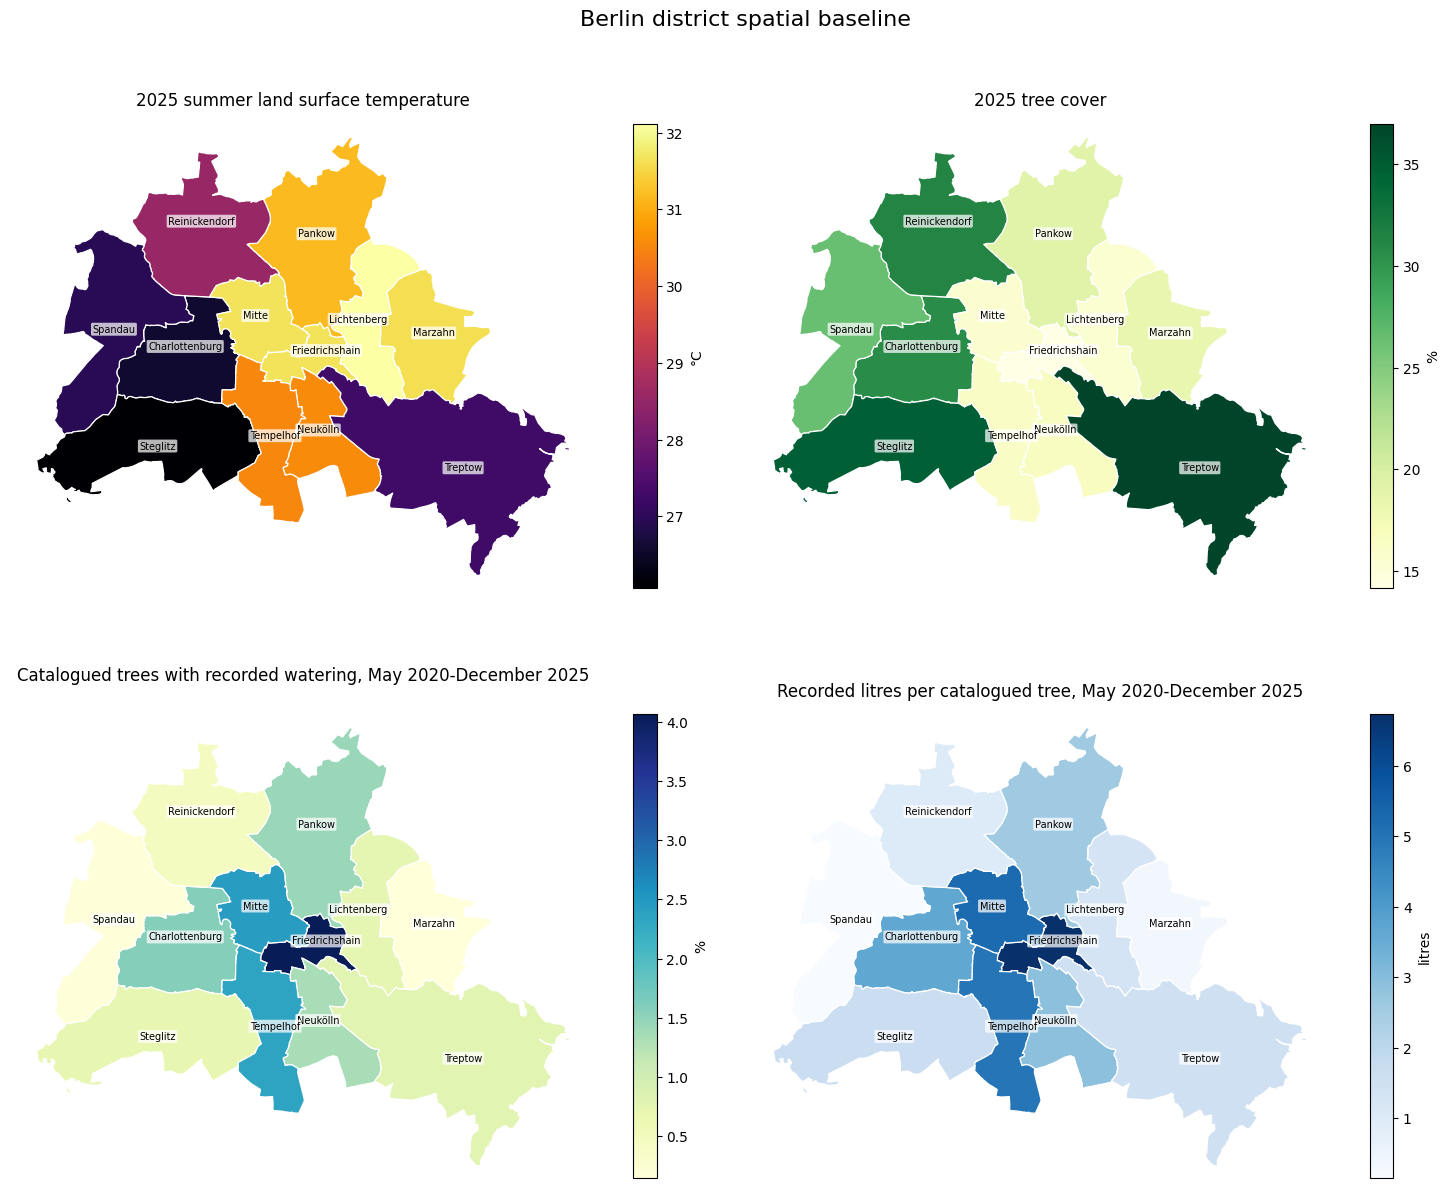

In [5]:
district_counts = (
    lor_metrics.groupby("District", as_index=False)
    .agg(
        inventory_trees=("inventory_trees", "sum"),
        watered_trees=("watered_trees", "sum"),
        watering_events=("watering_events", "sum"),
        total_litres=("total_litres", "sum"),
    )
)
district_counts["watering_reach_pct"] = (
    100 * district_counts["watered_trees"] / district_counts["inventory_trees"]
)
district_counts["litres_per_inventory_tree"] = (
    district_counts["total_litres"] / district_counts["inventory_trees"]
)

heat_raw = pd.read_csv(HEAT_FILE)
heat_2025 = heat_raw[
    (heat_raw["fclass"] == "admin_level9")
    & (heat_raw["season"] == "Summer")
    & (heat_raw["Year"] == 2025)
].copy()

districts = (
    lor[["District", "geometry"]]
    .dissolve(by="District", as_index=False)
    .merge(district_counts, on="District", how="left")
    .merge(
        heat_2025[
            ["District", "Landsat_LST_C", "TreeCover_Pct", "BuiltSurface_Pct"]
        ],
        on="District",
        how="left",
    )
)

map_specs = [
    ("Landsat_LST_C", "2025 summer land surface temperature", "inferno", "°C"),
    ("TreeCover_Pct", "2025 tree cover", "YlGn", "%"),
    (
        "watering_reach_pct",
        "Catalogued trees with recorded watering, May 2020-December 2025",
        "YlGnBu",
        "%",
    ),
    (
        "litres_per_inventory_tree",
        "Recorded litres per catalogued tree, May 2020-December 2025",
        "Blues",
        "litres",
    ),
]

fig, axes = plt.subplots(2, 2, figsize=(15, 13))
for ax, (column, title, cmap, unit) in zip(axes.flat, map_specs):
    districts.plot(
        column=column,
        cmap=cmap,
        edgecolor="white",
        linewidth=0.9,
        legend=True,
        legend_kwds={"label": unit, "shrink": 0.72},
        ax=ax,
    )
    for _, row in districts.iterrows():
        point = row.geometry.representative_point()
        label = row["District"].split("-")[0]
        ax.annotate(
            label,
            (point.x, point.y),
            ha="center",
            fontsize=7,
            bbox={
                "boxstyle": "round,pad=0.15",
                "facecolor": "white",
                "edgecolor": "none",
                "alpha": 0.72,
            },
        )
    ax.set_title(title, fontsize=12)
    ax.set_axis_off()

fig.suptitle("Berlin district spatial baseline", fontsize=16, y=0.98)
plt.tight_layout()
plt.savefig(
    FIGURES / "01_district_spatial_baseline.png",
    dpi=200,
    bbox_inches="tight",
)
plt.show()

## 4. Map neighbourhood watering reach and intensity

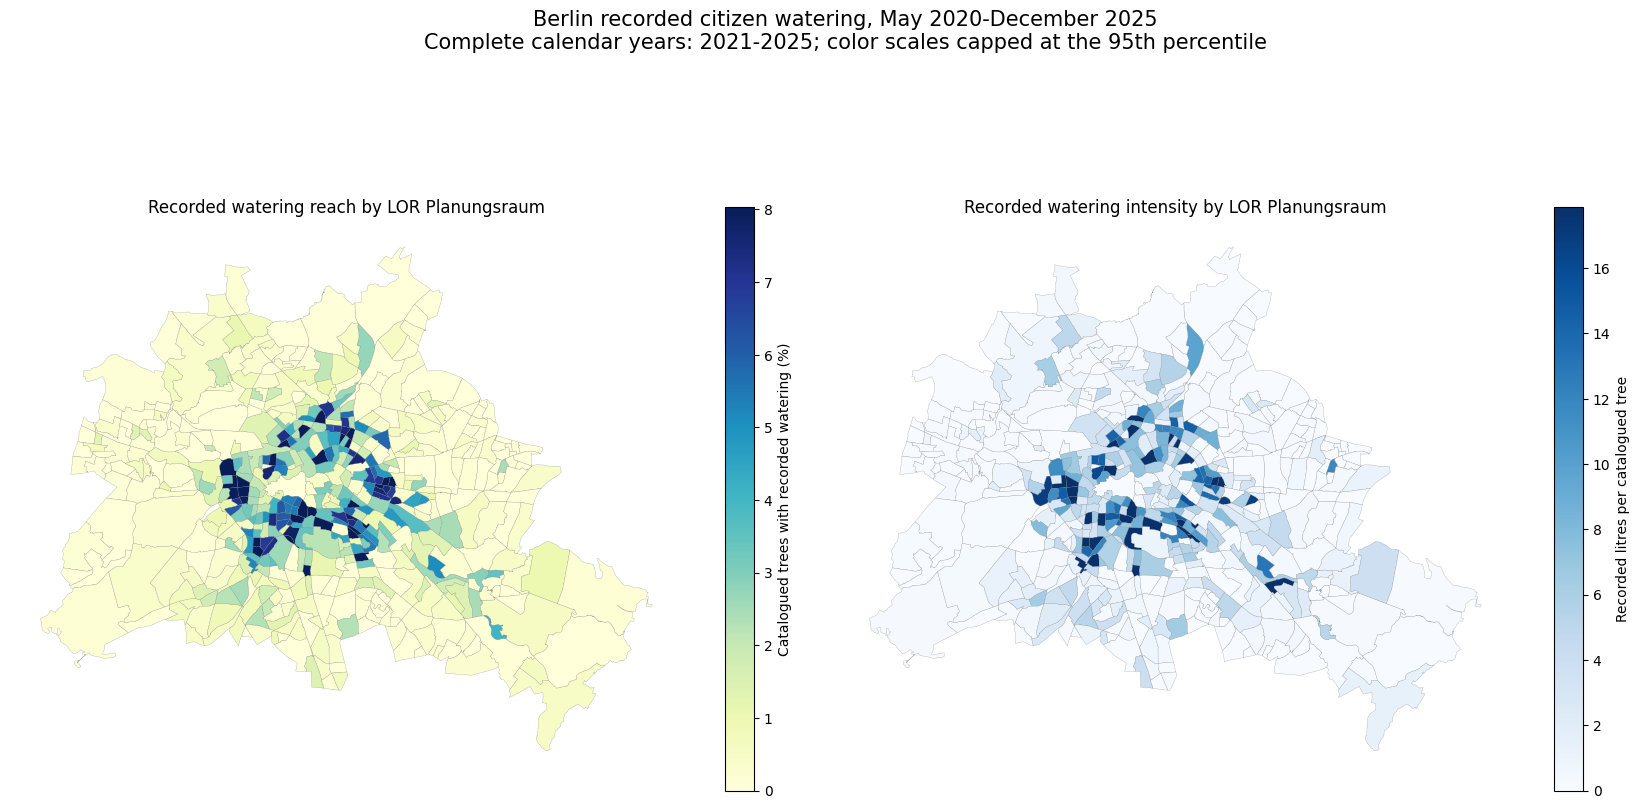

In [6]:
reach_vmax = lor_metrics["watering_reach_pct"].quantile(0.95)
intensity_vmax = lor_metrics["litres_per_inventory_tree"].quantile(0.95)

fig, axes = plt.subplots(1, 2, figsize=(17, 10))
lor_metrics.plot(
    column="watering_reach_pct",
    cmap="YlGnBu",
    vmin=0,
    vmax=reach_vmax,
    edgecolor="#777777",
    linewidth=0.15,
    legend=True,
    legend_kwds={"label": "Catalogued trees with recorded watering (%)", "shrink": 0.64},
    ax=axes[0],
)
axes[0].set_title("Recorded watering reach by LOR Planungsraum")
axes[0].set_axis_off()

lor_metrics.plot(
    column="litres_per_inventory_tree",
    cmap="Blues",
    vmin=0,
    vmax=intensity_vmax,
    edgecolor="#777777",
    linewidth=0.15,
    legend=True,
    legend_kwds={"label": "Recorded litres per catalogued tree", "shrink": 0.64},
    ax=axes[1],
)
axes[1].set_title("Recorded watering intensity by LOR Planungsraum")
axes[1].set_axis_off()

fig.suptitle(
    "Berlin recorded citizen watering, May 2020-December 2025\n"
    "Complete calendar years: 2021-2025; color scales capped at the 95th percentile",
    fontsize=15,
    y=0.96,
)
plt.tight_layout()
plt.savefig(
    FIGURES / "02_lor_watering_reach_intensity.png",
    dpi=220,
    bbox_inches="tight",
)
plt.show()

## 5. Spatial autocorrelation

Global Moran's I tests whether similar values tend to occur in neighboring
Planungsräume. Local Moran categories identify candidate high-high and low-low
clusters. A queen-contiguity matrix treats polygons sharing an edge or vertex as
neighbors. The permutation p-values use a fixed seed and 999 permutations.

,metric,value
0,Moran's I,0.441
1,Expected I,-0.002
2,Permutation p-value,0.001
3,Permutations,999.000


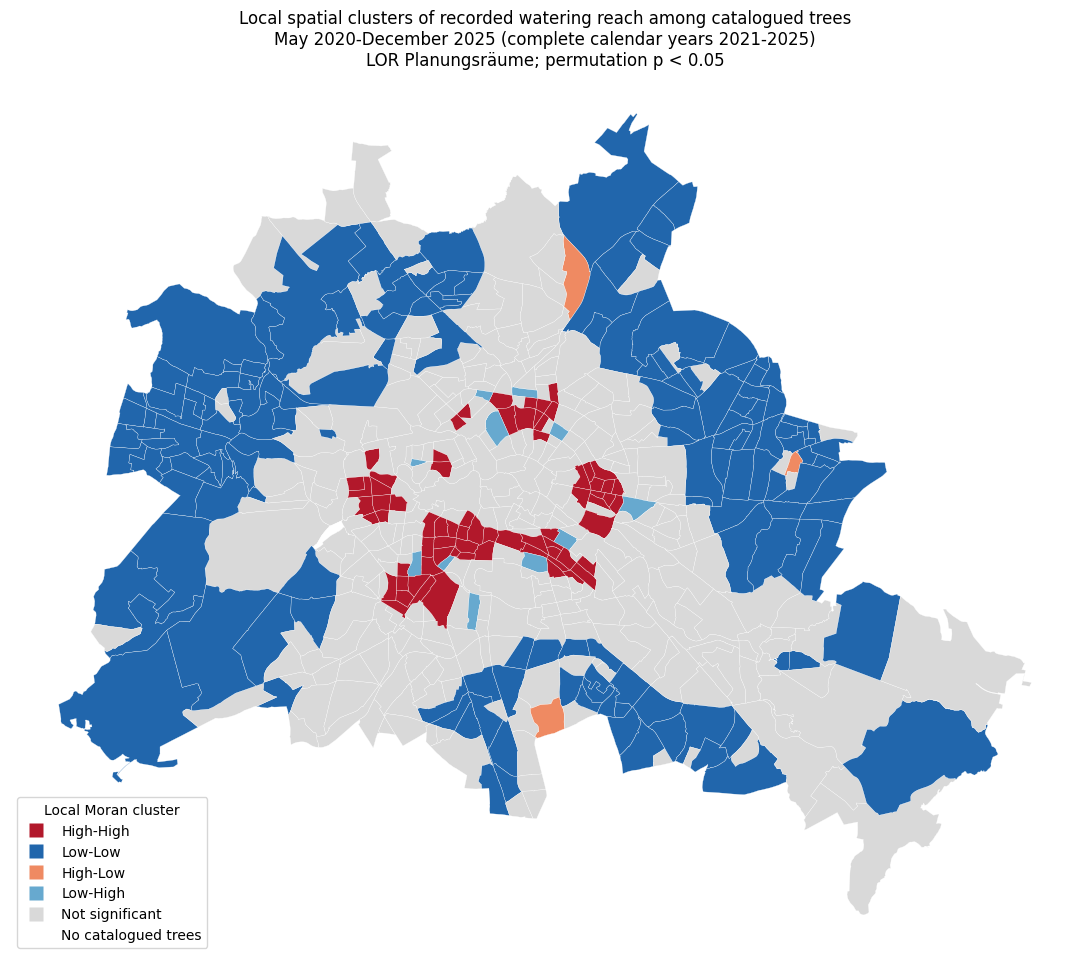

,plr_id,plr_name,bzr_name,District,watering_reach_pct,local_moran_cluster,local_moran_i,local_moran_p
76,02500728,Samariterviertel,Frankfurter Allee Nord,Friedrichshain-Kreuzberg,31.22,High-High,18.276,0.003
77,02500729,Pettenkofer Straße,Frankfurter Allee Nord,Friedrichshain-Kreuzberg,14.77,High-High,7.973,0.003
348,08100314,Donaustraße,Reuterstraße,Neukölln,14.64,High-High,4.279,0.017
301,07300515,Taunusstraße,Friedenau West,Tempelhof-Schöneberg,13.07,High-High,3.648,0.026
302,07300516,Odenwaldstraße,Friedenau West,Tempelhof-Schöneberg,10.54,High-High,4.134,0.012
128,03601244,Humannplatz,Prenzlauer Berg Nord,Pankow,9.93,High-High,2.725,0.027
130,03601346,Gethsemanekirche,Helmholtzplatz,Pankow,8.78,High-High,2.205,0.042
167,04300623,Karl-August-Platz,Otto-Suhr-Allee/Kantstraße,Charlottenburg-Wilmersdorf,8.72,High-High,2.720,0.010
292,07100206,Großgörschenstraße,Schöneberg Nordost,Tempelhof-Schöneberg,8.66,High-High,2.296,0.012
165,04300621,Richard-Wagner-Straße,Otto-Suhr-Allee/Kantstraße,Charlottenburg-Wilmersdorf,8.60,High-High,2.944,0.007


In [7]:
lor_indexed = lor_metrics.set_index("plr_id").copy()
analysis_lor = lor_indexed[lor_indexed["watering_reach_pct"].notna()].copy()
weights = Queen.from_dataframe(analysis_lor, use_index=True)
weights.transform = "r"

y = analysis_lor["watering_reach_pct"].to_numpy()
global_moran = Moran(y, weights, permutations=999)
local_moran = Moran_Local(y, weights, permutations=999, seed=42)

global_results = pd.DataFrame(
    {
        "metric": ["Moran's I", "Expected I", "Permutation p-value", "Permutations"],
        "value": [
            global_moran.I,
            global_moran.EI,
            global_moran.p_sim,
            global_moran.permutations,
        ],
    }
)
global_results.to_csv(TABLES / "global_moran_watering_reach.csv", index=False)
display(global_results)

quadrant_labels = {1: "High-High", 2: "Low-High", 3: "Low-Low", 4: "High-Low"}
significant = local_moran.p_sim < 0.05
clusters = np.where(
    significant,
    pd.Series(local_moran.q).map(quadrant_labels),
    "Not significant",
)
analysis_lor["local_moran_cluster"] = clusters
analysis_lor["local_moran_i"] = local_moran.Is
analysis_lor["local_moran_p"] = local_moran.p_sim
lor_indexed = lor_indexed.join(
    analysis_lor[
        ["local_moran_cluster", "local_moran_i", "local_moran_p"]
    ]
)
lor_indexed["local_moran_cluster"] = lor_indexed[
    "local_moran_cluster"
].fillna("No catalogued trees")
lor_metrics = lor_indexed.reset_index()

cluster_order = [
    "High-High", "Low-Low", "High-Low", "Low-High",
    "Not significant", "No catalogued trees",
]
cluster_colors = [
    "#b2182b", "#2166ac", "#ef8a62", "#67a9cf", "#d9d9d9", "#ffffff",
]
cluster_cmap = ListedColormap(cluster_colors)
lor_metrics["cluster_code"] = pd.Categorical(
    lor_metrics["local_moran_cluster"],
    categories=cluster_order,
    ordered=True,
).codes

fig, ax = plt.subplots(figsize=(11, 11))
lor_metrics.plot(
    column="cluster_code",
    categorical=True,
    cmap=cluster_cmap,
    edgecolor="white",
    linewidth=0.2,
    legend=False,
    ax=ax,
)
handles = [
    plt.Line2D(
        [0], [0], marker="s", linestyle="", markersize=10,
        markerfacecolor=color, markeredgecolor="none", label=label
    )
    for label, color in zip(cluster_order, cluster_colors)
]
ax.legend(handles=handles, title="Local Moran cluster", loc="lower left")
ax.set_title(
    "Local spatial clusters of recorded watering reach among catalogued trees\n"
    "May 2020-December 2025 (complete calendar years 2021-2025)\n"
    "LOR Planungsräume; permutation p < 0.05"
)
ax.set_axis_off()
plt.tight_layout()
plt.savefig(
    FIGURES / "03_lor_local_moran_clusters.png",
    dpi=220,
    bbox_inches="tight",
)
plt.show()

cluster_table = lor_metrics[
    [
        "plr_id", "plr_name", "bzr_name", "District",
        "watering_reach_pct", "local_moran_cluster",
        "local_moran_i", "local_moran_p",
    ]
].sort_values(["local_moran_cluster", "watering_reach_pct"], ascending=[True, False])
cluster_table.to_csv(TABLES / "local_moran_watering_clusters.csv", index=False)

display(
    cluster_table[
        cluster_table["local_moran_cluster"].eq("High-High")
    ].head(20).style.format(
        {
            "watering_reach_pct": "{:.2f}",
            "local_moran_i": "{:.3f}",
            "local_moran_p": "{:.3f}",
        }
    )
)

## 6. Export an interactive map and analysis-ready polygons

In [8]:
output_gpkg = OUT / "lor_watering_metrics_2020_2025.gpkg"
if output_gpkg.exists():
    output_gpkg.unlink()
lor_metrics.to_file(output_gpkg, layer="lor_watering_metrics", driver="GPKG")

web_lor = lor_metrics.copy()
web_lor["geometry"] = web_lor.geometry.simplify(
    tolerance=5,
    preserve_topology=True,
)
web_lor = web_lor.to_crs(4326)
reach_cap = float(web_lor["watering_reach_pct"].quantile(0.95))
litres_cap = float(web_lor["litres_per_inventory_tree"].quantile(0.95))
reach_scale = linear.YlGnBu_09.scale(0, reach_cap)
litres_scale = linear.Blues_09.scale(0, litres_cap)

interactive_map = folium.Map(
    location=[52.52, 13.405],
    zoom_start=10,
    tiles="CartoDB positron",
    control_scale=True,
)

tooltip_fields = [
    "plr_name", "bzr_name", "District", "inventory_trees",
    "watered_trees", "watering_reach_pct",
    "total_litres", "litres_per_inventory_tree",
    "local_moran_cluster",
]
tooltip_aliases = [
    "Planungsraum:", "Bezirksregion:", "District:", "Catalogued trees:",
    "Trees with recorded watering:", "Recorded watering reach (%):",
    "Recorded litres:", "Recorded litres per catalogued tree:",
    "Local Moran cluster:",
]

folium.GeoJson(
    web_lor,
    name="Recorded watering reach",
    show=True,
    style_function=lambda feature: {
        "fillColor": reach_scale(
            min(feature["properties"].get("watering_reach_pct") or 0, reach_cap)
        ),
        "color": "#666666",
        "weight": 0.35,
        "fillOpacity": 0.78,
    },
    tooltip=folium.GeoJsonTooltip(
        fields=tooltip_fields,
        aliases=tooltip_aliases,
        localize=True,
        sticky=False,
    ),
).add_to(interactive_map)

folium.GeoJson(
    web_lor,
    name="Recorded litres per catalogued tree",
    show=False,
    style_function=lambda feature: {
        "fillColor": litres_scale(
            min(
                feature["properties"].get("litres_per_inventory_tree") or 0,
                litres_cap,
            )
        ),
        "color": "#666666",
        "weight": 0.35,
        "fillOpacity": 0.78,
    },
    tooltip=folium.GeoJsonTooltip(
        fields=tooltip_fields,
        aliases=tooltip_aliases,
        localize=True,
        sticky=False,
    ),
).add_to(interactive_map)

reach_scale.caption = "Catalogued trees with recorded watering (%) - capped at 95th percentile"
reach_scale.add_to(interactive_map)
folium.LayerControl(collapsed=False).add_to(interactive_map)

map_file = MAPS / "lor_watering_interactive.html"
interactive_map.save(map_file)

print(f"Saved enriched polygons: {output_gpkg.relative_to(ROOT)}")
print(f"Saved interactive map: {map_file.relative_to(ROOT)}")
display(
    HTML(
        '<a href="../spatial/maps/lor_watering_interactive.html" target="_blank">'
        "Open the interactive LOR watering map</a>"
    )
)

Saved enriched polygons: output/spatial/lor_watering_metrics_2020_2025.gpkg
Saved interactive map: output/spatial/maps/lor_watering_interactive.html


## 7. Reproducible findings summary

In [9]:
high_high = lor_metrics[
    lor_metrics["local_moran_cluster"].eq("High-High")
].sort_values("watering_reach_pct", ascending=False)
low_low = lor_metrics[
    lor_metrics["local_moran_cluster"].eq("Low-Low")
].sort_values("watering_reach_pct")

findings = {
    "tree_assignment_rate": float(assigned.mean()),
    "lor_with_any_watering": int((lor_metrics["watered_trees"] > 0).sum()),
    "lor_total": int(len(lor_metrics)),
    "median_reach_pct": float(lor_metrics["watering_reach_pct"].median()),
    "moran_i": float(global_moran.I),
    "moran_p": float(global_moran.p_sim),
    "high_high_clusters": int(len(high_high)),
    "low_low_clusters": int(len(low_low)),
}

print("Key reproducible results")
for key, value in findings.items():
    print(f"- {key}: {value}")

print("\nHighest-reach high-high clusters:")
display(
    high_high[
        ["plr_name", "bzr_name", "District", "watering_reach_pct"]
    ].head(10).style.format({"watering_reach_pct": "{:.2f}"})
)

Key reproducible results
- tree_assignment_rate: 0.9990453255983446
- lor_with_any_watering: 462
- lor_total: 542
- median_reach_pct: 0.6451116790031045
- moran_i: 0.4405453105454913
- moran_p: 0.001
- high_high_clusters: 71
- low_low_clusters: 152

Highest-reach high-high clusters:


,plr_name,bzr_name,District,watering_reach_pct
76,Samariterviertel,Frankfurter Allee Nord,Friedrichshain-Kreuzberg,31.22
77,Pettenkofer Straße,Frankfurter Allee Nord,Friedrichshain-Kreuzberg,14.77
348,Donaustraße,Reuterstraße,Neukölln,14.64
301,Taunusstraße,Friedenau West,Tempelhof-Schöneberg,13.07
302,Odenwaldstraße,Friedenau West,Tempelhof-Schöneberg,10.54
128,Humannplatz,Prenzlauer Berg Nord,Pankow,9.93
130,Gethsemanekirche,Helmholtzplatz,Pankow,8.78
167,Karl-August-Platz,Otto-Suhr-Allee/Kantstraße,Charlottenburg-Wilmersdorf,8.72
292,Großgörschenstraße,Schöneberg Nordost,Tempelhof-Schöneberg,8.66
165,Richard-Wagner-Straße,Otto-Suhr-Allee/Kantstraße,Charlottenburg-Wilmersdorf,8.60


## Interpretation and next step

- These maps reveal within-district variation that was hidden by the original
  12-district summaries.
- Inventory-normalized reach is preferable to raw event counts because dense
  tree inventories create more opportunities for logged watering.
- High-high clusters are candidate concentrations of volunteer activity, while
  low-low clusters identify contiguous areas with limited recorded reach.
- The cluster map is sensitive to the LOR boundary system, the selected
  contiguity weights, and the cumulative 2020-2025 time window.
- The next defensible join is LOR-level social vulnerability and environmental
  justice data. Heat values currently remain district-level and should not be
  copied to Planungsräume as if they were neighbourhood observations.